# ❤️ Heart Disease Prediction – Model Building

**Objective:** Build and evaluate machine-learning models that predict whether a patient has heart disease
from clinical parameters (age, sex, chest pain type, blood pressure, cholesterol, ECG, heart rate, etc.),
and save the final model, scaler and feature columns for use in the Streamlit app.

**Workflow**
1. Import libraries
2. Load dataset
3. Data cleaning
4. Exploratory data analysis (EDA)
5. Feature engineering & preprocessing
6. Hyperparameter tuning (KNN)
7. Model building (Logistic Regression, KNN, Random Forest)
8. Cross-validation

9. Save model artifacts

## 1. Import Libraries


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
import warnings
warnings.filterwarnings('ignore')

## 2. Load Dataset

**Objective:** Read the heart disease dataset and take a first look at its structure, columns and data types.

In [3]:
df = pd.read_csv("ht.csv")

In [4]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,52,M,ASY,160.0,203,0,Normal,141.0,Y,0.5,Flat,1
1,54,Male,NAP,108.0,0,0,Normal,98.0,N,0.7,Flat,1
2,58,M,ASY,147.0,0,1,NaN,138.0,N,1.2,Flat,1
3,58,M,ASY,118.0,223,1,LVH,129.0,N,1.4,Up,1
4,65,M,ASY,102.0,363,1,Normal,167.0,N,0.5,Flat,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             14793 non-null  object 
 1   Sex             14851 non-null  object 
 2   ChestPainType   15000 non-null  object 
 3   RestingBP       14687 non-null  float64
 4   Cholesterol     14608 non-null  object 
 5   FastingBS       15000 non-null  int64  
 6   RestingECG      14694 non-null  object 
 7   MaxHR           14765 non-null  float64
 8   ExerciseAngina  15000 non-null  object 
 9   Oldpeak         14699 non-null  float64
 10  ST_Slope        14754 non-null  object 
 11  HeartDisease    15000 non-null  int64  
dtypes: float64(3), int64(2), object(7)
memory usage: 1.4+ MB


## 3. Data Cleaning

**Objective:** Inspect the data first (null values, unique values, data types, duplicates, outliers),
then fix each problem column by column so the data is ready for analysis and modelling.

### 3.1 Initial Data Inspection


**a) Shape of the dataset** – number of rows and columns

In [6]:
print("Rows   :", df.shape[0])
print("Columns:", df.shape[1])

Rows   : 15000
Columns: 12


**b) Data types** 

In [7]:
df.dtypes

Age                object
Sex                object
ChestPainType      object
RestingBP         float64
Cholesterol        object
FastingBS           int64
RestingECG         object
MaxHR             float64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object

**c) Null (missing) values** 

In [8]:
null_summary = pd.DataFrame({
    "Null Count": df.isnull().sum(),
    "Null %": (df.isnull().sum() / len(df) * 100).round(2)
})
null_summary

,Null Count,Null %
Age,207,1.38
Sex,149,0.99
ChestPainType,0,0.00
RestingBP,313,2.09
Cholesterol,392,2.61
FastingBS,0,0.00
RestingECG,306,2.04
MaxHR,235,1.57
ExerciseAngina,0,0.00
Oldpeak,301,2.01


**d) Duplicate rows** 

In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 150


**e) Number of unique values** 

In [10]:
df.nunique()

Age                53
Sex                10
ChestPainType       9
RestingBP         116
Cholesterol       331
FastingBS           2
RestingECG          3
MaxHR             145
ExerciseAngina      6
Oldpeak            78
ST_Slope            7
HeartDisease        2
dtype: int64

**f) Unique values of categorical columns**

In [11]:
categorical_cols = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]

for col in categorical_cols:
    print(f"--- {col} ---")
    print("Unique values:", df[col].unique())
    print(df[col].value_counts(dropna=False))
    print()

--- Sex ---
Unique values: ['M' 'Male' 'F' 'F ' nan 'Female' 'male' ' M' 'm' 'female' 'f']
M         11042
F          2948
Male        198
 M          167
male        162
m           150
NaN         149
female       53
Female       52
f            40
F            39
Name: Sex, dtype: int64

--- ChestPainType ---
Unique values: ['ASY' 'NAP' 'TA' 'ATA' 'ta' 'nap' 'asy' ' ASY' 'ata']
ASY     7794
NAP     3226
ATA     2781
TA       743
 ASY     135
asy      118
ata       87
nap       84
ta        32
Name: ChestPainType, dtype: int64

--- RestingECG ---
Unique values: ['Normal' nan 'LVH' 'ST']
Normal    8801
LVH       3053
ST        2840
NaN        306
Name: RestingECG, dtype: int64

--- ExerciseAngina ---
Unique values: ['Y' 'N' 'n' 'y' 'Yes' 'No']
N      8676
Y      5721
n       183
No      179
Yes     124
y       117
Name: ExerciseAngina, dtype: int64

--- ST_Slope ---
Unique values: ['Flat' 'Up' 'Down' 'up' ' Flat' 'down' nan 'flat']
Flat     7176
Up       6166
Down      972
NaN       2

**g) Statistical summary**

In [12]:
df.describe()

,RestingBP,FastingBS,MaxHR,Oldpeak,HeartDisease
count,14687.000000,15000.000000,14765.000000,14699.000000,15000.000000
mean,132.974331,0.236800,137.037250,0.890061,0.553267
std,19.754374,0.425133,26.104187,1.081232,0.497171
min,80.000000,0.000000,20.000000,-2.600000,0.000000
25%,121.000000,0.000000,119.000000,0.100000,0.000000
50%,133.000000,0.000000,137.000000,0.800000,1.000000
75%,144.000000,0.000000,155.000000,1.500000,1.000000
max,400.000000,1.000000,300.000000,5.900000,1.000000


### 3.2 Age
**Objective:** Convert to numeric, fill missing values with the mean and store as integer.

In [13]:
# 🔍 Check
print("Data type      :", df["Age"].dtype)
print("Missing values :", df["Age"].isnull().sum())
print("Unique values  :", df["Age"].nunique())

# Values that are not numbers (e.g. text like "forty")
non_numeric = df.loc[pd.to_numeric(df["Age"], errors="coerce").isnull() & df["Age"].notnull(), "Age"]
print("Non-numeric values:", non_numeric.unique())

Data type      : object
Missing values : 207
Unique values  : 53
Non-numeric values: ['unknown']


In [14]:
# 🛠️ Fix
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["Age"] = df["Age"].fillna(df["Age"].mean())
df["Age"] = df["Age"].astype(int)

In [ ]:
# ✅ Verify
print("Data type      :", df["Age"].dtype)
print("Missing values :", df["Age"].isnull().sum())
print("Min / Max      :", df["Age"].min(), "/", df["Age"].max()) 

Data type      : int32
Missing values : 0
Min / Max      : -5 / 150


### 3.3 Sex
**Objective:** Fill missing values with the mode, remove extra spaces, convert to lowercase
and standardize categories

In [16]:
# 🔍 Check
print("Data type      :", df["Sex"].dtype)
print("Missing values :", df["Sex"].isnull().sum())
print("Unique values  :", df["Sex"].unique())
print()
print(df["Sex"].value_counts(dropna=False))

Data type      : object
Missing values : 149
Unique values  : ['M' 'Male' 'F' 'F ' nan 'Female' 'male' ' M' 'm' 'female' 'f']

M         11042
F          2948
Male        198
 M          167
male        162
m           150
NaN         149
female       53
Female       52
f            40
F            39
Name: Sex, dtype: int64


In [17]:
# 🛠️ Fix
df["Sex"] = df["Sex"].fillna(df["Sex"].mode()[0])

# Remove extra spaces
df["Sex"] = df["Sex"].str.strip()

# Convert all values to lowercase
df["Sex"] = df["Sex"].str.lower()

# Standardize categories
df["Sex"] = df["Sex"].replace({
    "m": "male",
    "f": "female"
})

# Convert missing text "nan" into actual missing value
df["Sex"] = df["Sex"].replace("nan", np.nan)

In [18]:
# ✅ Verify
print("Missing values :", df["Sex"].isnull().sum())
print("Unique values  :", df["Sex"].unique())
print()
print(df["Sex"].value_counts(dropna=False))

Missing values : 0
Unique values  : ['male' 'female']

male      11868
female     3132
Name: Sex, dtype: int64


### 3.4 Cholesterol
**Objective:** Convert to numeric and fill missing values with the median (robust to outliers).

In [19]:
# 🔍 Check
print("Data type      :", df["Cholesterol"].dtype)
print("Missing values :", df["Cholesterol"].isnull().sum())
print("Unique values  :", df["Cholesterol"].nunique())

non_numeric = df.loc[pd.to_numeric(df["Cholesterol"], errors="coerce").isnull() & df["Cholesterol"].notnull(), "Cholesterol"]
print("Non-numeric values:", non_numeric.unique())

print()
print(pd.to_numeric(df["Cholesterol"], errors="coerce").describe())

Data type      : object
Missing values : 392
Unique values  : 331
Non-numeric values: ['?']

count    14571.000000
mean       198.404777
std        113.150428
min          0.000000
25%        165.000000
50%        227.000000
75%        270.000000
max       1500.000000
Name: Cholesterol, dtype: float64


In [20]:
# 🛠️ Fix
df["Cholesterol"] = pd.to_numeric(df["Cholesterol"], errors="coerce")
df["Cholesterol"] = df["Cholesterol"].fillna(df["Cholesterol"].median())

In [21]:
# ✅ Verify
print("Data type      :", df["Cholesterol"].dtype)
print("Missing values :", df["Cholesterol"].isnull().sum())

Data type      : float64
Missing values : 0


### 3.5 RestingBP
**Objective:** Convert to numeric, treat unrealistic values (> 250 mm Hg) as missing
and fill them with the median.

In [22]:
# 🔍 Check
print("Data type      :", df["RestingBP"].dtype)
print("Missing values :", df["RestingBP"].isnull().sum())
print("Unique values  :", df["RestingBP"].nunique())

bp = pd.to_numeric(df["RestingBP"], errors="coerce")
print("Non-numeric values:", df.loc[bp.isnull() & df["RestingBP"].notnull(), "RestingBP"].unique())
print("Values above 250  :", (bp > 250).sum())
print()
print(bp.describe())

Data type      : float64
Missing values : 313
Unique values  : 116
Non-numeric values: []
Values above 250  : 20

count    14687.000000
mean       132.974331
std         19.754374
min         80.000000
25%        121.000000
50%        133.000000
75%        144.000000
max        400.000000
Name: RestingBP, dtype: float64


In [23]:
# 🛠️ Fix
df["RestingBP"] = pd.to_numeric(df["RestingBP"], errors="coerce")

# Unrealistic blood pressure values -> missing
df.loc[df["RestingBP"] > 250, "RestingBP"] = np.nan

df["RestingBP"] = df["RestingBP"].fillna(df["RestingBP"].median())

In [24]:
# ✅ Verify
print("Missing values :", df["RestingBP"].isnull().sum())
print("Min / Max      :", df["RestingBP"].min(), "/", df["RestingBP"].max())

Missing values : 0
Min / Max      : 80.0 / 200.0


### 3.6 RestingECG
**Objective:** Fill missing values with the most frequent category (mode).

In [25]:
# 🔍 Check
print("Missing values :", df["RestingECG"].isnull().sum())
print("Unique values  :", df["RestingECG"].unique())
print()
print(df["RestingECG"].value_counts(dropna=False))

Missing values : 306
Unique values  : ['Normal' nan 'LVH' 'ST']

Normal    8801
LVH       3053
ST        2840
NaN        306
Name: RestingECG, dtype: int64


In [26]:
# 🛠️ Fix
df["RestingECG"] = df["RestingECG"].fillna(df["RestingECG"].mode()[0])

In [27]:
# ✅ Verify
print("Missing values :", df["RestingECG"].isnull().sum())
print(df["RestingECG"].value_counts(dropna=False))

Missing values : 0
Normal    9107
LVH       3053
ST        2840
Name: RestingECG, dtype: int64


### 3.7 MaxHR
**Objective:** Fill missing values with the median.

In [28]:
# 🔍 Check
print("Data type      :", df["MaxHR"].dtype)
print("Missing values :", df["MaxHR"].isnull().sum())
print("Unique values  :", df["MaxHR"].nunique())
print()
print(df["MaxHR"].describe())

Data type      : float64
Missing values : 235
Unique values  : 145

count    14765.000000
mean       137.037250
std         26.104187
min         20.000000
25%        119.000000
50%        137.000000
75%        155.000000
max        300.000000
Name: MaxHR, dtype: float64


In [29]:
# 🛠️ Fix
df["MaxHR"] = df["MaxHR"].fillna(df["MaxHR"].median())

In [30]:
# ✅ Verify
print("Missing values :", df["MaxHR"].isnull().sum())

Missing values : 0


### 3.8 Oldpeak
**Objective:** Fill missing values with the median.

In [31]:
# 🔍 Check
print("Data type      :", df["Oldpeak"].dtype)
print("Missing values :", df["Oldpeak"].isnull().sum())
print("Unique values  :", df["Oldpeak"].nunique())
print()
print(df["Oldpeak"].describe())

Data type      : float64
Missing values : 301
Unique values  : 78

count    14699.000000
mean         0.890061
std          1.081232
min         -2.600000
25%          0.100000
50%          0.800000
75%          1.500000
max          5.900000
Name: Oldpeak, dtype: float64


In [32]:
# 🛠️ Fix
df["Oldpeak"] = df["Oldpeak"].fillna(df["Oldpeak"].median())

In [33]:
# ✅ Verify
print("Missing values :", df["Oldpeak"].isnull().sum())

Missing values : 0


### 3.9 ST_Slope
**Objective:** Remove extra spaces, fill missing values with the mode and convert to lowercase.

In [34]:
# 🔍 Check
print("Missing values :", df["ST_Slope"].isnull().sum())
print("Unique values  :", df["ST_Slope"].unique())
print()
print(df["ST_Slope"].value_counts(dropna=False))

Missing values : 246
Unique values  : ['Flat' 'Up' 'Down' 'up' ' Flat' 'down' nan 'flat']

Flat     7176
Up       6166
Down      972
NaN       246
up        181
 Flat     117
flat      110
down       32
Name: ST_Slope, dtype: int64


In [35]:
# 🛠️ Fix
df["ST_Slope"] = df["ST_Slope"].apply(
    lambda x: x.strip() if isinstance(x, str) else x
)

df["ST_Slope"] = df["ST_Slope"].fillna(df["ST_Slope"].mode()[0])

df["ST_Slope"] = df["ST_Slope"].str.lower()

In [36]:
# ✅ Verify
print("Missing values :", df["ST_Slope"].isnull().sum())
print("Unique values  :", df["ST_Slope"].unique())
print(df["ST_Slope"].value_counts(dropna=False))

Missing values : 0
Unique values  : ['flat' 'up' 'down']
flat    7649
up      6347
down    1004
Name: ST_Slope, dtype: int64


### 3.10 ChestPainType
**Objective:** Remove extra spaces and convert to uppercase (TA, ATA, NAP, ASY).

In [37]:
# 🔍 Check
print("Missing values :", df["ChestPainType"].isnull().sum())
print("Unique values  :", df["ChestPainType"].unique())
print()
print(df["ChestPainType"].value_counts(dropna=False))

Missing values : 0
Unique values  : ['ASY' 'NAP' 'TA' 'ATA' 'ta' 'nap' 'asy' ' ASY' 'ata']

ASY     7794
NAP     3226
ATA     2781
TA       743
 ASY     135
asy      118
ata       87
nap       84
ta        32
Name: ChestPainType, dtype: int64


In [38]:
# 🛠️ Fix
df["ChestPainType"] = (
    df["ChestPainType"]
    .str.strip()
    .str.upper()
)

In [39]:
# ✅ Verify
print("Unique values  :", df["ChestPainType"].unique())
print(df["ChestPainType"].value_counts(dropna=False))

Unique values  : ['ASY' 'NAP' 'TA' 'ATA']
ASY    8047
NAP    3310
ATA    2868
TA      775
Name: ChestPainType, dtype: int64


### 3.11 Remove Duplicates
**Objective:** Find duplicate rows, drop them and confirm none are left.

In [40]:
# 🔍 Check
print("Rows before        :", df.shape[0])
print("Duplicate rows     :", df.duplicated().sum())

Rows before        : 15000
Duplicate rows     : 150


In [41]:
# 🛠️ Fix
df = df.drop_duplicates()

In [42]:
# ✅ Verify
print("Rows after         :", df.shape[0])
print("Duplicate rows left:", df.duplicated().sum())

Rows after         : 14850
Duplicate rows left: 0


### 3.12 Final Data Check
**Objective:** Confirm the whole dataset is clean – no missing values, correct data types
and consistent unique values in every categorical column.

In [43]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 14850 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             14850 non-null  int32  
 1   Sex             14850 non-null  object 
 2   ChestPainType   14850 non-null  object 
 3   RestingBP       14850 non-null  float64
 4   Cholesterol     14850 non-null  float64
 5   FastingBS       14850 non-null  int64  
 6   RestingECG      14850 non-null  object 
 7   MaxHR           14850 non-null  float64
 8   ExerciseAngina  14850 non-null  object 
 9   Oldpeak         14850 non-null  float64
 10  ST_Slope        14850 non-null  object 
 11  HeartDisease    14850 non-null  int64  
dtypes: float64(4), int32(1), int64(2), object(5)
memory usage: 1.4+ MB


In [45]:
for col in ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]:
    print(f"{col:15}:", df[col].unique())

Sex            : ['male' 'female']
ChestPainType  : ['ASY' 'NAP' 'TA' 'ATA']
RestingECG     : ['Normal' 'LVH' 'ST']
ExerciseAngina : ['Y' 'N' 'n' 'y' 'Yes' 'No']
ST_Slope       : ['flat' 'up' 'down']


## 4. Exploratory Data Analysis (EDA)

### 4.1 Age vs Heart Disease

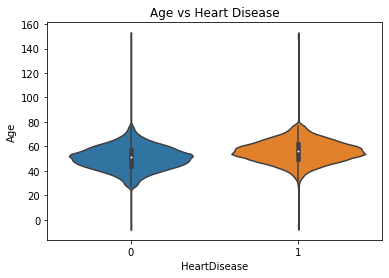

In [46]:
sns.violinplot(x='HeartDisease', y='Age', data=df)
plt.title("Age vs Heart Disease")
plt.show()

### 4.2 Chest Pain Type vs Heart Disease


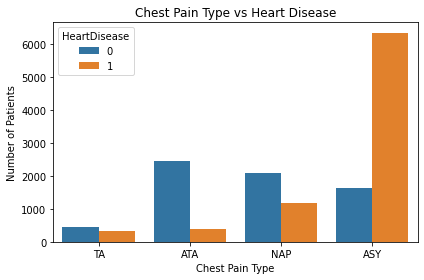

In [47]:
sns.countplot(
    data=df,
    x="ChestPainType",
    hue="HeartDisease",
    order=["TA", "ATA", "NAP", "ASY"]
)

plt.title("Chest Pain Type vs Heart Disease")
plt.xlabel("Chest Pain Type")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

### 4.3 Cholesterol vs Heart Disease
**Objective:** Compare cholesterol levels and spot outliers for both groups.

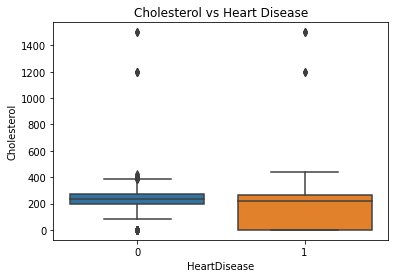

In [48]:
sns.boxplot(x='HeartDisease', y='Cholesterol', data=df)
plt.title("Cholesterol vs Heart Disease")
plt.show()

### 4.4 Correlation Heatmap
**Objective:** Find which numeric features are most correlated with each other and with the target.

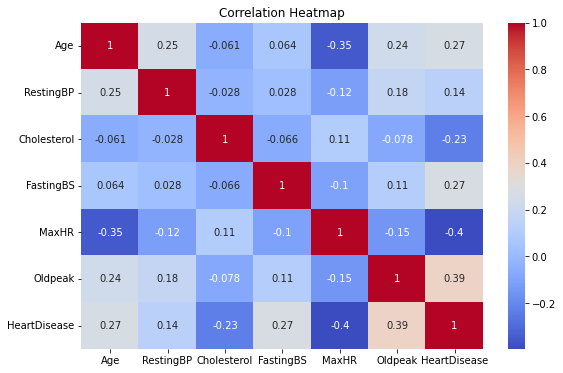

In [49]:
plt.figure(figsize=(9, 6))

numeric_df = df.select_dtypes(include="number")

# Correlation heatmap
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [50]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,52,male,ASY,160.0,203.0,0,Normal,141.0,Y,0.5,flat,1
1,54,male,NAP,108.0,0.0,0,Normal,98.0,N,0.7,flat,1
2,58,male,ASY,147.0,0.0,1,Normal,138.0,N,1.2,flat,1
3,58,male,ASY,118.0,223.0,1,LVH,129.0,N,1.4,up,1
4,65,male,ASY,102.0,363.0,1,Normal,167.0,N,0.5,flat,1


In [51]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

## 5. Feature Engineering & Preprocessing


### 5.1 One-Hot Encoding
**Objective:** Convert categorical columns into numeric dummy columns (`drop_first=True` avoids redundant columns).

In [53]:
df_encoded = pd.get_dummies(df, drop_first=True)
df_encoded = df_encoded.astype(int)
df_encoded

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_male,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_No,ExerciseAngina_Y,ExerciseAngina_Yes,ExerciseAngina_n,ExerciseAngina_y,ST_Slope_flat,ST_Slope_up
0,52,160,203,0,141,0,1,1,0,0,0,1,0,0,1,0,0,0,1,0
1,54,108,0,0,98,0,1,1,0,1,0,1,0,0,0,0,0,0,1,0
2,58,147,0,1,138,1,1,1,0,0,0,1,0,0,0,0,0,0,1,0
3,58,118,223,1,129,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1
4,65,102,363,1,167,0,1,1,0,0,0,1,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,51,126,285,0,144,0,1,1,0,0,0,1,0,0,1,0,0,0,1,0
14996,49,157,253,0,129,0,1,0,0,0,1,1,0,0,1,0,0,0,1,0
14997,44,117,232,0,202,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1
14998,42,139,255,0,137,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1


### 5.2 Features and Target
**Objective:** Separate input features (`X`) from the target column (`HeartDisease`).

In [54]:
X = df_encoded.drop(columns=['HeartDisease'])
y = df_encoded['HeartDisease']

### 5.3 Train-Test Split
**Objective:** Keep 80% of the data for training and 20% for testing the models.

In [55]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

### 5.4 Label Encoding of Target
**Objective:** Make sure the target labels are encoded as 0 and 1.

In [56]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

### 5.5 Feature Scaling
**Objective:** Standardize features (mean 0, std 1). The scaler is fitted on training data only
to avoid data leakage, and this same scaler is saved for the Streamlit app.

In [57]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 6. Hyperparameter Tuning (KNN)

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Create pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Parameters to test
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}

# Cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid Search
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=1,       # Changed from -1
    verbose=1,
    error_score="raise"
)

# Train and tune
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Score:", grid_search.best_score_)

Fitting 5 folds for each of 28 candidates, totalling 140 fits


## 7. Model Building

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

### Model 1: Logistic Regression

In [ ]:
LR_model = LogisticRegression(random_state=42, max_iter=1000)
LR_model.fit(X_train_scaled, y_train)

y_pred_LR = LR_model.predict(X_test_scaled)
y_pred_LR

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_LR))
print(classification_report(y_test, y_pred_LR))

Accuracy: 0.9138047138047138
              precision    recall  f1-score   support

           0       0.90      0.90      0.90      1320
           1       0.92      0.92      0.92      1650

    accuracy                           0.91      2970
   macro avg       0.91      0.91      0.91      2970
weighted avg       0.91      0.91      0.91      2970



### Model 2: K-Nearest Neighbors (KNN)

In [ ]:
KNN_model = KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=1)
KNN_model.fit(X_train_scaled, y_train)

y_pred_KNN = KNN_model.predict(X_test_scaled)
y_pred_KNN

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_KNN))
print(classification_report(y_test, y_pred_KNN))

Accuracy: 0.9037037037037037
              precision    recall  f1-score   support

           0       0.89      0.90      0.89      1320
           1       0.92      0.91      0.91      1650

    accuracy                           0.90      2970
   macro avg       0.90      0.90      0.90      2970
weighted avg       0.90      0.90      0.90      2970



### Model 3: Random Forest

In [ ]:
RF_model = RandomForestClassifier(n_estimators=100, random_state=42)
RF_model.fit(X_train_scaled, y_train)

y_pred_RF = RF_model.predict(X_test_scaled)
y_pred_RF

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_RF))
print(classification_report(y_test, y_pred_RF))

Accuracy: 0.9154882154882155
              precision    recall  f1-score   support

           0       0.91      0.90      0.90      1320
           1       0.92      0.93      0.92      1650

    accuracy                           0.92      2970
   macro avg       0.91      0.91      0.91      2970
weighted avg       0.92      0.92      0.92      2970



## 8. Cross-Validation

**Objective:** Check that the Random Forest result is stable and not just lucky on one train-test split,
by using 5-fold cross-validation on the training data.


In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(RF_model, X_train, y_train, cv=5, scoring='accuracy')
print("Fold scores:", scores)
print("Mean accuracy:", scores.mean())

Fold scores: [0.91877104 0.91456229 0.90530303 0.91161616 0.91245791]
Mean accuracy: 0.9125420875420875


## 9. Save Model Artifacts

**Objective:** Save the trained model, the scaler and the feature column names with `joblib`
so the Streamlit app can load them and make predictions in the same format as training.

| File | Contents |
|---|---|
| `ht.pkl` | Trained Logistic Regression model |
| `scaler.pkl` | StandardScaler fitted on training data |
| `heart_columns.pkl` | Feature column names / order |

In [ ]:
import joblib

joblib.dump(LR_model, "ht.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(X_train.columns, "heart_columns.pkl")

print("Model, scaler and columns saved successfully.")